<a id="chapter-12"></a>

# Chapter 12 · Actor-Critic Methods - A2C and A3C / Actor-Critic

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 actor 与 critic 的分工
- 写出 A2C 联合损失
- 区分同步 A2C 与异步 A3C

**开始前最好已经会：**

- 掌握 REINFORCE 与 baseline
- 理解一步 TD target
- 能区分 policy 与 value 输出


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Variance reduction / CartPole variance | baseline 与实验直觉 | 详细 |
| Advantage Actor-Critic (A2C) | TD advantage、联合 loss | 详细 |
| A2C on Pong / tuning | 源码路线 | 完整 |
| Asynchronous A3C | 梯度并行与同步 | 详细 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

REINFORCE 要等整局结束且方差很大。能否边玩边学习，并让一个网络告诉 actor‘这一步比预期好多少’？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

critic 估计价值并形成低方差 advantage；actor 用 advantage 更新策略。A2C 同步汇总多个环境，A3C 由异步 worker 更新共享参数。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| actor | 策略 $\pi_\theta$ | 决定动作 |
| critic | 价值 $V_\phi$ | 评价状态 |
| $\delta_t$ | TD residual | 一步 surprise |
| $\hat A_t$ | advantage 估计 | actor 的加权信号 |
| $c_v,c_e$ | value/entropy 系数 | 平衡联合 loss |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 用 critic 构造低方差 baseline

理想 advantage 为 $A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s)$。未知 $Q$ 时，用一步样本近似：

$$Q^\pi(s_t,a_t)\approx R_{t+1}+\gamma V_\phi(s_{t+1})$$

所以

$$\hat A_t=R_{t+1}+\gamma(1-d_t)V_\phi(s_{t+1})-V_\phi(s_t)$$

这同时是 TD error。

### 2. actor 与 critic 各学什么

actor 最大化 $\log\pi(a_t|s_t)\hat A_t$，实现中最小化其负数。critic 回归 bootstrap target：

$$L_V=\tfrac12(V_\phi(s_t)-y_t)^2=\tfrac12\hat A_t^2$$

联合目标常写成

$$L=L_{actor}+c_vL_V-c_eH(\pi)$$

actor 使用 `advantage.detach()`，避免策略项通过 advantage 意外更新 critic。

### 3. A2C 与 A3C 的差别

A2C 同步等待多个环境收集一段 rollout，再组成 batch 更新；A3C 的 worker 异步对共享模型施加梯度。核心 actor-critic 数学相同，主要区别是并发与数据时效。


## 4. 手算一个最小例子


$r=1,\gamma=0.9,V(s)=0.4,V(s')=0.5$，未终止：

$$y=1+0.9\times0.5=1.45,\quad \hat A=1.45-0.4=1.05$$

正 advantage 表示结果比 critic 原先预期好，actor 应提高该动作概率。若真正终止，则 $y=1$，advantage 为 0.6。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 一步 actor-critic

$$\hat A_t=R_{t+1}+\gamma(1-d_t)V_\phi(S_{t+1})-V_\phi(S_t)$$

$$L_{actor}=-\log\pi_\theta(A_t|S_t)\,\operatorname{stopgrad}(\hat A_t)$$

$$L_{critic}=\tfrac12\hat A_t^2,\qquad L=L_{actor}+c_vL_{critic}-c_eH(\pi)$$

实际代码常用 n-step return 替代一步 TD。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $V(s_t)$ | `value` | critic 当前预测，需梯度 |
| $V(s_{t+1})$ | `next_value` | 构造 target 时停止梯度 |
| $y_t$ | `reward + gamma * (~terminated) * next_value` | bootstrap target |
| $\hat A_t$ | `target - value` | actor 权重兼 critic residual |
| $L_{actor}$ | `-(log_prob * advantage.detach()).mean()` | 不经 advantage 回传 |
| $L_V$ | `0.5 * advantage.square().mean()` | 更新 critic |

**从公式过渡到代码时：**单元格展示联合 loss 的 shape 与梯度路径。终止 mask 只屏蔽真正 terminal 的 bootstrap。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import torch

log_prob = torch.tensor([-0.2, -1.0, -0.5], requires_grad=True)
value = torch.tensor([0.4, 0.2, 0.1], requires_grad=True)
next_value = torch.tensor([0.5, 0.3, 0.0])
reward = torch.tensor([1.0, 0.0, -0.2])
terminated = torch.tensor([False, False, True])
gamma = 0.99

target = reward + gamma * (~terminated) * next_value
advantage = target - value
actor_loss = -(log_prob * advantage.detach()).mean()
critic_loss = 0.5 * advantage.square().mean()
loss = actor_loss + 0.5 * critic_loss
loss.backward()
print({"target": target.detach().tolist(), "loss": loss.item()})


{'target': [1.4950000047683716, 0.2970000207424164, -0.20000000298023224], 'loss': 0.1635361909866333}


### 怎样读运行结果

输出 target 第三个样本应等于 reward，因为它终止。去掉 `detach` 虽然代码仍运行，但 actor loss 会额外沿 value 分支传播，改变我们定义的优化目标。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
同步 A2C：
并行 N 个环境收集 T 步 rollout
若最后状态未终止，用 critic bootstrap
从后向前计算 n-step returns 或 GAE advantages
一次前向得到 policy logits 与 values
actor_loss = -log_prob * stopgrad(advantage)
critic_loss = (return - value)^2
loss = actor + cv*critic - ce*entropy
对 N*T 样本更新共享网络

A3C：多个 worker 各自采样/算梯度，将梯度异步施加到共享参数。
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

# GAE: delta_t 的指数加权和；lambda=0 近似一步 TD，lambda→1 接近长回报。
deltas = np.array([1.0, 0.5, -0.2])
gamma, lam = 0.99, 0.95
gae = np.zeros_like(deltas)
running = 0.0
for t in range(len(deltas) - 1, -1, -1):
    running = deltas[t] + gamma * lam * running
    gae[t] = running
print("GAE:", np.round(gae, 4))


GAE: [ 1.2933  0.3119 -0.2   ]


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_cartpole_pg.py`](../../Chapter12/01_cartpole_pg.py) | CartPole actor-critic | 低维验证 advantage |
| [`02_pong_a2c.py`](../../Chapter12/02_pong_a2c.py) | Pong A2C | n-step rollout 与联合网络 |
| [`02_pong_a2c_tune.py`](../../Chapter12/02_pong_a2c_tune.py) | 调参入口 | 评价协议与搜索空间 |
| [`03_a3c_grad.py`](../../Chapter12/03_a3c_grad.py) | 梯度 worker | 参数/梯度跨进程传递 |
| [`common.py`](../../Chapter12/lib/common.py) | unpack/loss 工具 | 公式到 tensor 的集中映射 |

<details>
<summary>为什么按这个顺序读</summary>

A2C 关键不是‘两个网络’，而是 bootstrap return 如何与 rollout 边界对齐。跟踪每个环境最后状态的 `last_value`，真正终止为 0，截断或 rollout 切片仍应估值。A3C 重点检查 worker 梯度是否对应某个参数快照、主进程何时清梯度，以及异步延迟是否可接受。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**Actor-Critic 的平均回报和 critic 估值

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


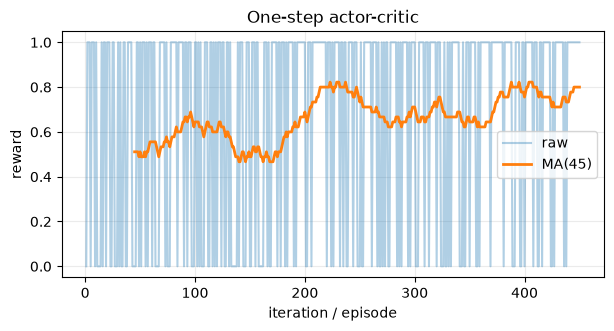

critic V: 0.895 P(best action): 0.866


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(12)
theta, value = 0.0, 0.0
rewards, values = [], []
for episode in range(450):
    p = 1 / (1 + np.exp(-theta))
    action = float(rng.random() < p)
    reward = float(rng.random() < (0.3 if action == 0 else 0.8))
    advantage = reward - value
    value += 0.08 * advantage
    theta += 0.06 * advantage * (action - p)
    rewards.append(reward); values.append(value)

plot_curve(rewards, "One-step actor-critic", "reward", window=45)
print("critic V:", round(value, 3), "P(best action):", round(1 / (1 + np.exp(-theta)), 3))


### 曲线怎么读

回报移动平均应接近最优臂的成功率 0.8，critic 也应靠近当前策略的平均回报。critic loss 下降但 reward 不升，通常说明 actor 数据流或 advantage 符号有问题。

### 调参过程：一次只改变一个因素

- 先分别记录 policy loss、value loss、entropy、episode return。
- 让 critic 学习率略高于 actor，先确认 value 能跟上策略分布。
- 再调 n-step/GAE 和 entropy；一次只改一项并至少跑多种子。

### 失败案例复盘

- advantage 没有从 critic 图中分离，actor 更新反向改变 value target。
- A3C worker 梯度没有正确复制到共享模型。
- 只看 critic loss 很小，却没有检查策略回报。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- actor 和 critic 共用 backbone 时，两个 loss 都会更新共享层。
- value loss 系数过大可能压制策略学习。
- A3C 的并发 bug 难复现；学习时先让同步版本正确。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

去掉 `advantage.detach()`，查看 value 的梯度怎样变化，并解释为何这通常不是想要的 actor 更新。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

去掉 detach 后，actor loss 会通过 `advantage = target - value` 给 value 额外梯度；它可能推动 critic 仅为减小策略项而改变，而不是回归 return。比较 `value.grad` 可看到联合梯度与纯 critic loss 梯度不同。标准实现让 actor 与 critic 各自遵循定义好的目标。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- actor 决策，critic 评价。
- 一步 TD error 可作为 advantage 的低方差估计。
- 联合 loss 的各项更新不同参数路径。
- A2C/A3C 的数学主线相同，系统实现不同。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么 critic loss 可以写成 $\tfrac12\hat A^2$？actor loss 中为什么 detach advantage？

<details>
<summary>展开答案</summary>

因为 advantage 正是 bootstrap target 减当前 value，即 critic 的回归残差。detach 用于让策略项只更新 log-prob 路径，critic 由自己的 value loss 更新。
</details>


## 17. 与前后章节连接

第 15 章把 actor-critic 扩展到连续动作；第 16 章继续解决策略更新步子过大的稳定性问题。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

GAE 用指数加权 TD residual 平衡偏差与方差；V-trace 可修正分布式 actor 的 off-policy 数据。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-12) · [← 学习索引](../README.md)
